# 1. Create and inspect an SSP

As a first example, we will consider an idealised star cluster in which all the stars formed in a single burst and have the same initial chemical composition: a **simple stellar population (SSP)**. The stars in this population have different initial masses, drawn from an **initial mass function (IMF)** that specifies their relative abundance, and therefore evolve on different timescales.

In this tutorial, we will learn how create an SSP using ARSENAL's `SynthPop` class and inspect its sampled stellar masses.

Although we will not use the stellar-evolution interface yet, creating a `SynthPop` will also load the stellar-evolution data. If the required MIST tables are not available locally, ARSENAL will attempt to download them, so the first run may require an internet connection and take longer.

To follow the tutorial, run the cells in order in a Python environment with ARSENAL, NumPy, Matplotlib and Astropy installed. We will use Astropy's units module to attach physical units to quantities and to convert between them when needed.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import arsenal_gear as ag

We start by creating one simple stellar population (SSP) from a dictionary of formation parameters.

| Parameter | Meaning |
|---|---|
| `type` | Stellar-system type; `"single"` specifies a population of single stars. |
| `Mtot` | Target total initial stellar mass; the sampled mass can differ. |
| `tform` | Formation time of the component. |
| `metallicity` | Metallicity expressed as $\log_{10}(Z/Z_\odot)$; `0` means solar metallicity. |
| `rotation` | Stellar rotation expressed as a fraction of critical rotation. |
| `imf` | Initial mass function used to sample stellar masses. |
| `mmin`, `mmax` | Lower and upper initial-mass limits when selecting the IMF by name. If not specified, they are set to their defaults. |
| `discrete` | If `True`, sample individual stellar masses. |
| `seed` | Random seed used to make the sampling reproducible. |

`interp_op='iso'` selects interpolation using precomputed MIST isochrones to calculate stellar properties at the requested ages and initial masses. This is the default option.

`vvcrit="0.0"` selects the nonrotating MIST models, consistent with the population’s formation setting, `rotation=0.0`.

In [ ]:
ssp_parameters = {
    "type": "single",
    "Mtot": 1e5 * u.Msun,
    "tform": 0 * u.Myr,
    "metallicity": 0.0,
    "rotation": 0.0,
    "imf": "kroupa2001",
    "mmin": 0.1 * u.Msun,
    "mmax": 100 * u.Msun,
    "discrete": True,
    "seed": 42,
}

sp = ag.SynthPop(pop1=ssp_parameters, interp_op="iso", vvcrit="0.0")

We have now created a `SynthPop` containing one stellar component and its stellar-evolution interface. To inspect the component, we access `sp.form.subpops[0]`. This `SinglePop` object stores the formation parameters and sampled initial stellar masses.

In [8]:
pop = sp.form.subpops[0]

print("Number of stars:", pop.Nstar)
print("Target initial mass:", pop.Mtot)
print("Sampled initial mass:", pop.masses.sum())
print("First ten initial masses:", pop.masses[:10])

Number of stars: 174257
Target initial mass: 100000.0 solMass
Sampled initial mass: 99622.34431893835 solMass
First ten initial masses: [0.1742166  1.68078344 0.45652948 0.3082933  0.10825331 0.10824801
 0.08925012 0.78136242 0.31040629 0.42399758] solMass


Each entry in `pop.masses` is the initial mass of one sampled star, with physical units attached. As you might have noticed, their sum, the realized initial mass of the cluster, can differ from the target `Mtot`. This happens because, in order to draw a sample from the IMF, ARSENAL first chooses the number of stars as

$$
N_\star=\operatorname{round}\!\left(\frac{M_{\mathrm{target}}}{\langle m\rangle_{\mathrm{IMF}}}\right),
$$

and then randomly draws that many stellar masses, with probabilities determined by the IMF.

Let’s visualize the distribution of sampled initial stellar masses with a histogram and compare it with the expected number of stars in each bin predicted by the IMF. Differences between them reflect random sampling fluctuations in this realization.

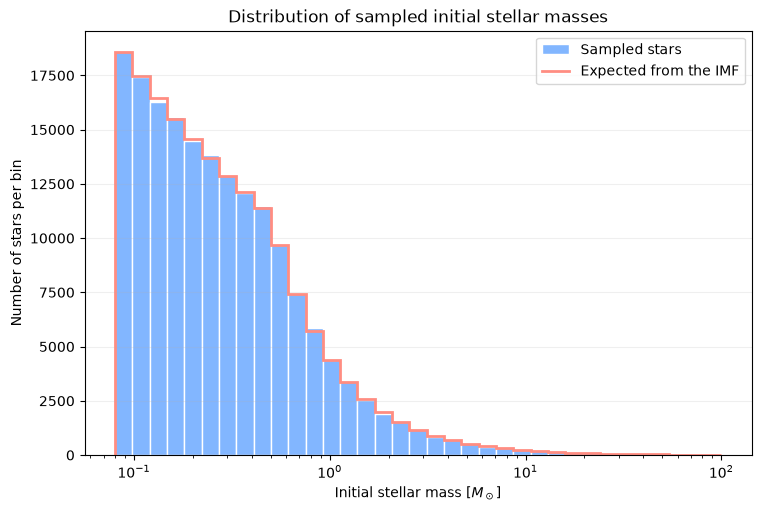

In [9]:
initial_masses = pop.masses.to_value(u.Msun)
mass_bins = np.geomspace(pop.imf.min_mass, pop.imf.max_mass, 36)
expected_counts = pop.Nstar * np.diff(pop.imf.cdf(mass_bins))

fig, ax = plt.subplots(figsize=(7.5, 5), layout="constrained")
counts, edges, patches = ax.hist(initial_masses, bins=mass_bins, color="#82B6FF", edgecolor="white", label="Sampled stars")
ax.stairs(expected_counts, mass_bins, color="#FF8D82", linewidth=2, label="Expected from the IMF")
ax.set_xscale("log")
ax.set_xlabel(r"Initial stellar mass [$M_\odot$]")
ax.set_ylabel("Number of stars per bin")
ax.set_title("Distribution of sampled initial stellar masses")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.show()

As an alternative, we can normalize the histogram using `density=True` and compare it directly with the IMF's normalized probability density, $\rho(M)$.

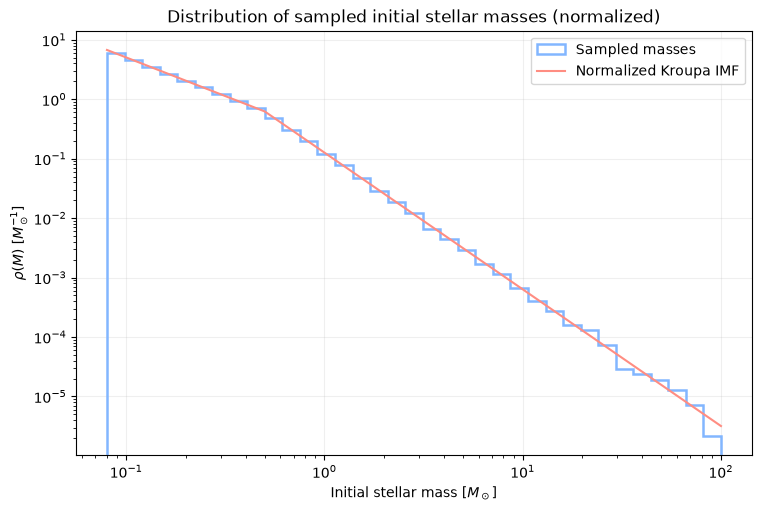

Histogram probability integral: 1.000000


In [10]:
mass_grid = np.geomspace(pop.imf.min_mass, pop.imf.max_mass, 500)

fig, ax = plt.subplots(figsize=(7.5, 5), layout="constrained")
density, density_edges, patches = ax.hist(initial_masses, bins=mass_bins, density=True, histtype="step", linewidth=1.8, color="#82B6FF", label="Sampled masses")
ax.plot(mass_grid, pop.imf.pdf(mass_grid), color="#FF8D82", label="Normalized Kroupa IMF")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"Initial stellar mass [$M_\odot$]")
ax.set_ylabel(r"$\rho(M)$ [$M_\odot^{-1}$]")
ax.set_title("Distribution of sampled initial stellar masses (normalized)")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

print(f"Histogram probability integral: {np.sum(density * np.diff(density_edges)):.6f}")

The density histogram fluctuates around the parent IMF because it contains a finite random sample. Fluctuations are particularly visible in sparsely populated high-mass bins.

So far, we have explored the initial stellar content stored in `sp.form`. In the next tutorial, we will see that the `SynthPop` object also provides methods to evaluate population-level properties at a specified time, using the stellar evolution interfaces in `sp.evol`.